# OCEANIS.ai — Freight Rate Dataset: EDA, Encoding & Correlation Heatmap
**Goal:** understand the dataset used to predict maritime bulk freight rates (USD/tonne) to the East Coast of India, and prepare it for model training.

**Sections**
1. Load & inspect
2. Data quality checks
3. Exploratory Data Analysis (univariate, time series, bivariate)
4. Outlier check
5. Encoding & feature engineering
6. Correlation heatmap
7. Save model-ready data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load & inspect

In [2]:
df = pd.read_csv("freight_dataset.csv", parse_dates=["date"])
print("Shape:", df.shape)
df.head(10)

Shape: (10956, 7)


,date,distance,route_popularity,fuel_rate,urgency,bdi,freight_rate
0,2021-01-01,"15,378.00",23.50,600.00,3,"1,800.00",32.85
1,2021-01-01,"9,116.90",37.70,600.00,1,"1,800.00",20.68
2,2021-01-01,"8,589.90",83.30,600.00,2,"1,800.00",19.26
3,2021-01-01,"4,409.10",34.40,600.00,2,"1,800.00",11.07
4,2021-01-01,"9,090.70",23.20,600.00,3,"1,800.00",22.19
5,2021-01-01,"4,417.80",54.40,600.00,5,"1,800.00",12.88
6,2021-01-02,"4,813.20",100.00,610.00,4,"1,757.00",11.76
7,2021-01-02,"14,914.20",11.80,610.00,4,"1,757.00",34.29
8,2021-01-02,"15,530.90",21.60,610.00,4,"1,757.00",36.04
9,2021-01-02,"6,112.20",46.30,610.00,4,"1,757.00",16.04


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10956 entries, 0 to 10955
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              10956 non-null  datetime64[us]
 1   distance          10956 non-null  float64       
 2   route_popularity  10956 non-null  float64       
 3   fuel_rate         10956 non-null  float64       
 4   urgency           10956 non-null  int64         
 5   bdi               10956 non-null  float64       
 6   freight_rate      10956 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 599.3 KB


In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,10956,2023-07-02 12:00:00,2021-01-01 00:00:00,2022-04-02 00:00:00,2023-07-02 12:00:00,2024-10-01 00:00:00,2025-12-31 00:00:00,NaN
distance,"10,956.00","9,334.04","4,247.70","5,873.80","8,832.00","10,748.45","16,765.80","4,186.83"
route_popularity,"10,956.00",40.92,1.00,23.50,38.80,56.60,100.00,23.99
fuel_rate,"10,956.00",621.31,535.00,599.90,625.95,643.30,704.40,30.19
urgency,"10,956.00",2.76,1.00,2.00,3.00,4.00,5.00,1.17
bdi,"10,956.00","1,669.85",986.00,"1,507.00","1,657.50","1,812.00","2,432.00",280.62
freight_rate,"10,956.00",20.89,6.98,13.22,18.93,26.50,51.22,9.16


**Columns**
| Column | Meaning |
|---|---|
| `date` | Shipment/booking date |
| `distance` | Sea distance between load and discharge port (km, from `searoute`) |
| `route_popularity` | Route traffic proxy, 1–100 |
| `fuel_rate` | VLSFO bunker price (USD/tonne) |
| `urgency` | 1 = flexible … 5 = immediate |
| `bdi` | Baltic Dry Index |
| `freight_rate` | **Target** — USD/tonne |

## 2. Data quality checks

In [5]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df.date.min().date(), "→", df.date.max().date())
print("Unique days:", df.date.nunique())
print("Rows per day (min/max):", df.groupby("date").size().min(), "/", df.groupby("date").size().max())

Missing values per column:
 date                0
distance            0
route_popularity    0
fuel_rate           0
urgency             0
bdi                 0
freight_rate        0
dtype: int64 

Duplicate rows: 0
Date range: 2021-01-01 → 2025-12-31
Unique days: 1826
Rows per day (min/max): 6 / 6


In [6]:
print("Unique values per column:")
print(df.nunique())
print("\nUrgency distribution:")
print(df.urgency.value_counts().sort_index())

Unique values per column:
date                1826
distance            9321
route_popularity      62
fuel_rate            912
urgency                5
bdi                  877
freight_rate        3175
dtype: int64

Urgency distribution:
urgency
1    1597
2    3255
3    3326
4    1706
5    1072
Name: count, dtype: int64


## 3. Exploratory Data Analysis
### 3.1 Distributions

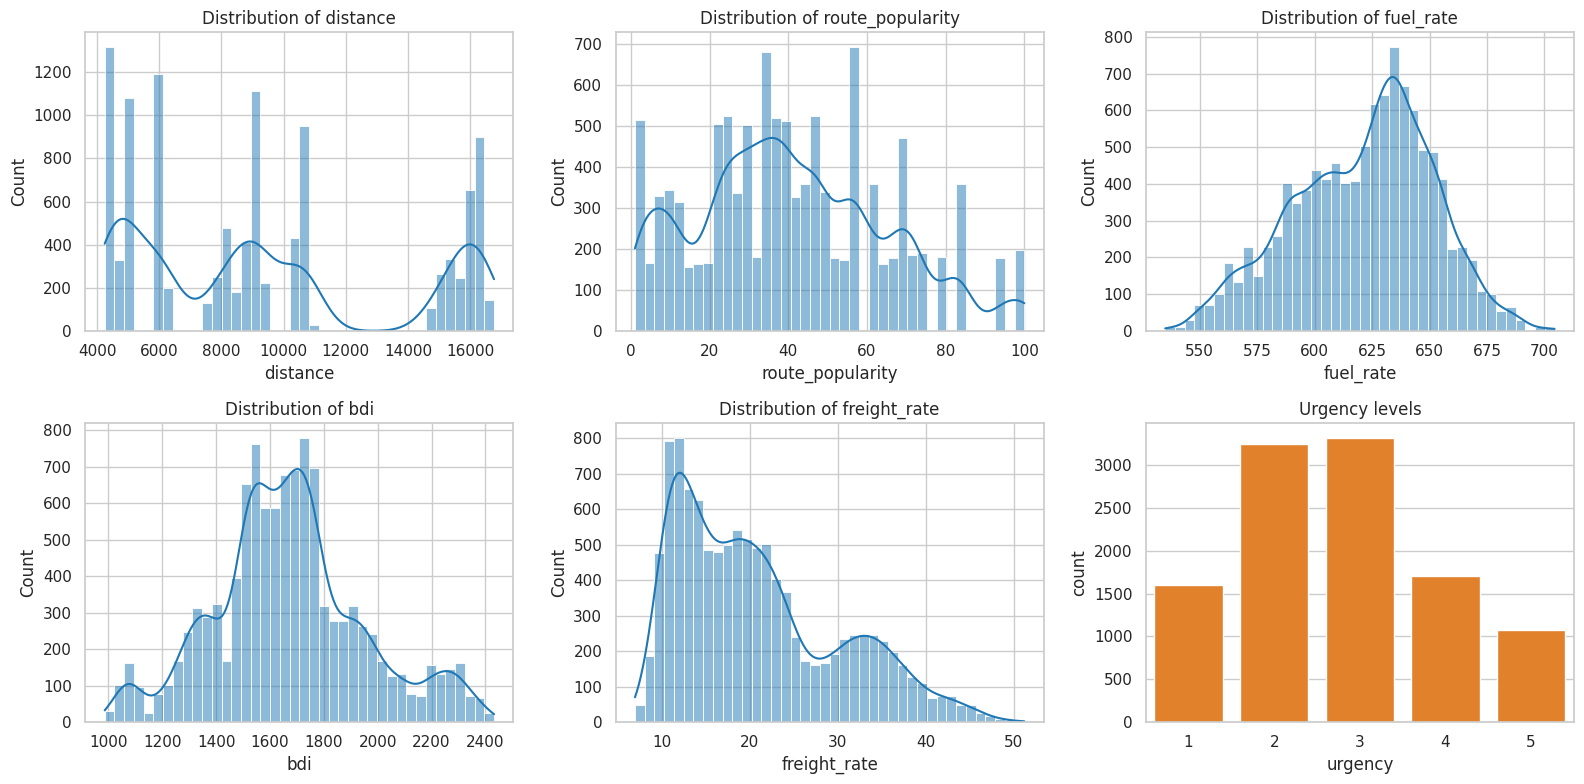

In [7]:
num_cols = ["distance", "route_popularity", "fuel_rate", "bdi", "freight_rate"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color="#1f77b4")
    ax.set_title(f"Distribution of {col}")
sns.countplot(x="urgency", data=df, ax=axes.ravel()[5], color="#ff7f0e")
axes.ravel()[5].set_title("Urgency levels")
plt.tight_layout(); plt.show()

In [8]:
print("Skewness:")
print(df[num_cols].skew())

Skewness:
distance            0.53
route_popularity    0.36
fuel_rate          -0.28
bdi                 0.28
freight_rate        0.77
dtype: float64


### 3.2 Time series: BDI, fuel and freight rate

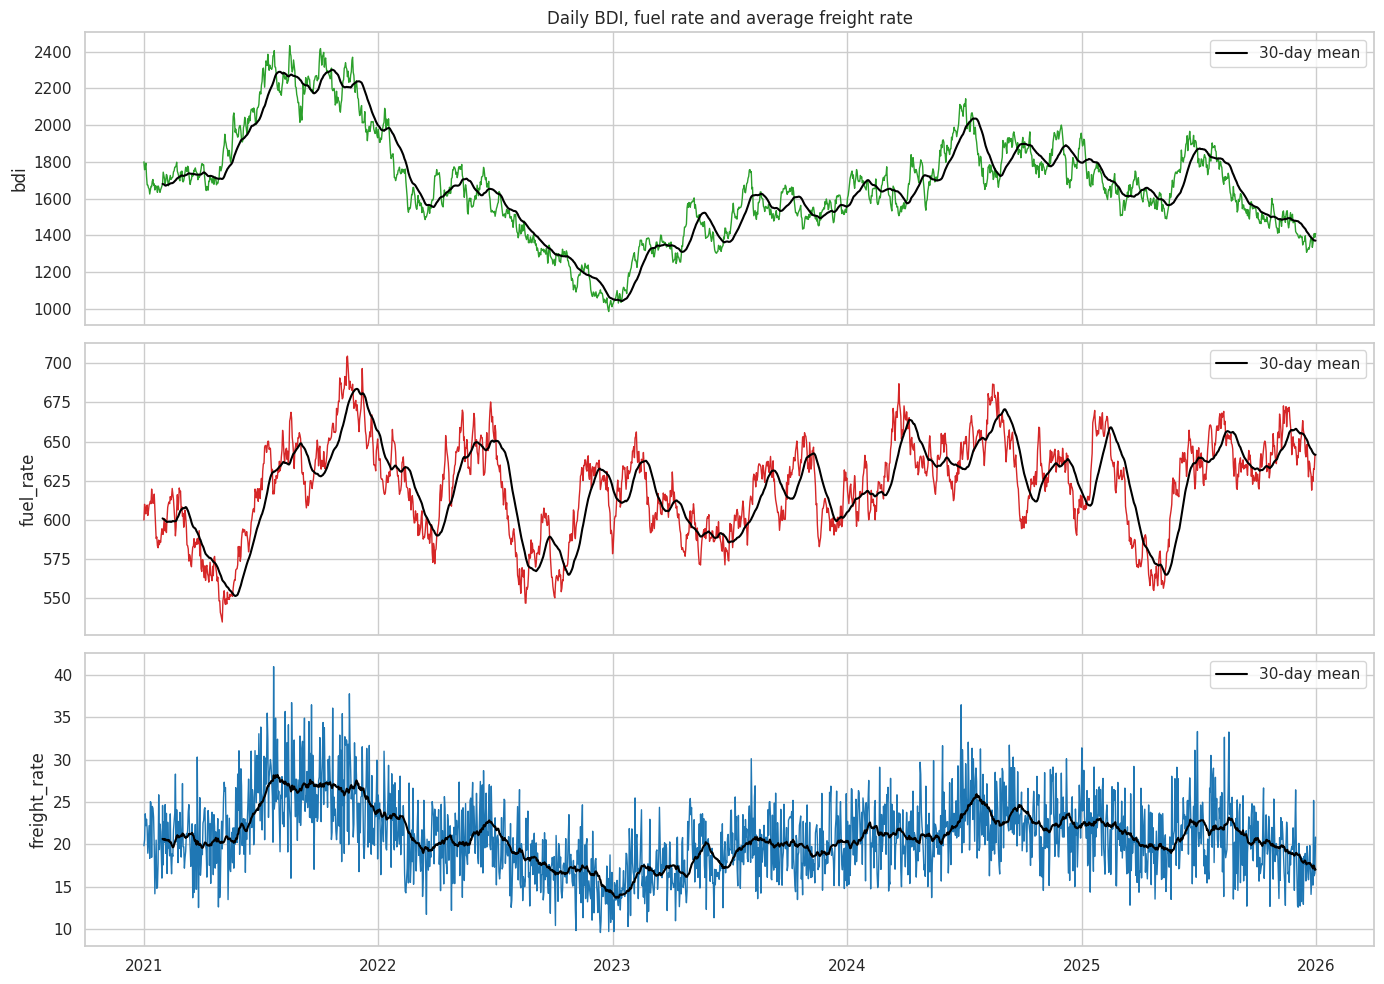

In [9]:
daily = df.groupby("date")[["bdi", "fuel_rate", "freight_rate"]].mean()
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col, c in zip(axes, ["bdi", "fuel_rate", "freight_rate"], ["#2ca02c", "#d62728", "#1f77b4"]):
    ax.plot(daily.index, daily[col], color=c, lw=1)
    ax.plot(daily[col].rolling(30).mean(), color="black", lw=1.5, label="30-day mean")
    ax.set_ylabel(col); ax.legend(loc="upper right")
axes[0].set_title("Daily BDI, fuel rate and average freight rate")
plt.tight_layout(); plt.show()

### 3.3 Seasonality

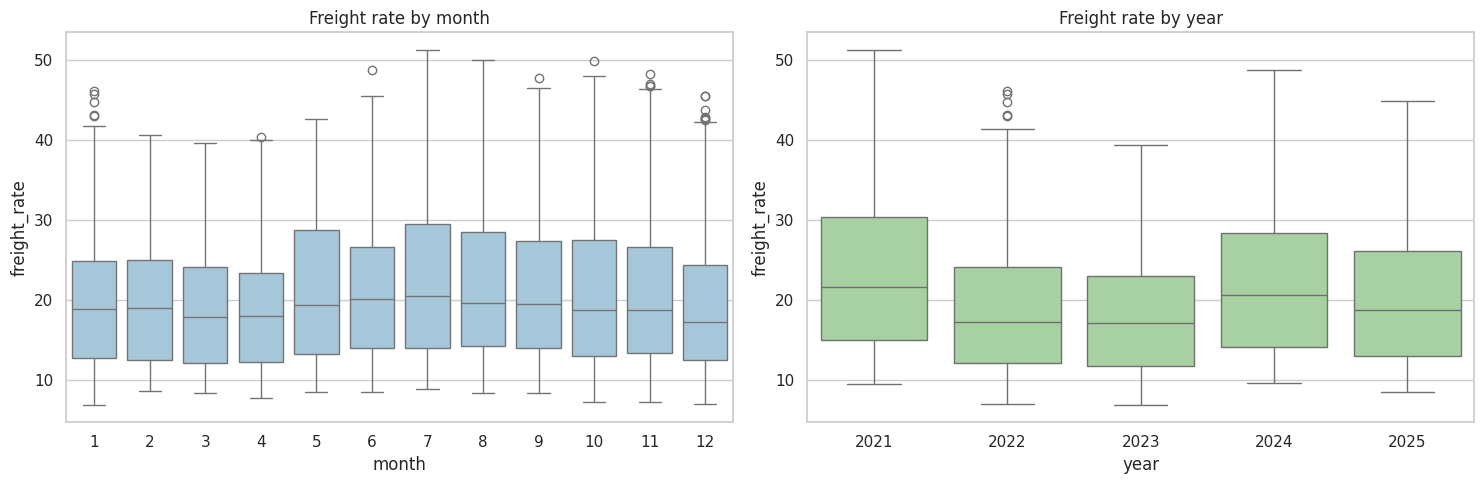

In [10]:
df["year"] = df.date.dt.year
df["month"] = df.date.dt.month
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(x="month", y="freight_rate", data=df, ax=axes[0], color="#9ecae1")
axes[0].set_title("Freight rate by month")
sns.boxplot(x="year", y="freight_rate", data=df, ax=axes[1], color="#a1d99b")
axes[1].set_title("Freight rate by year")
plt.tight_layout(); plt.show()

### 3.4 Relationship of each feature with freight rate

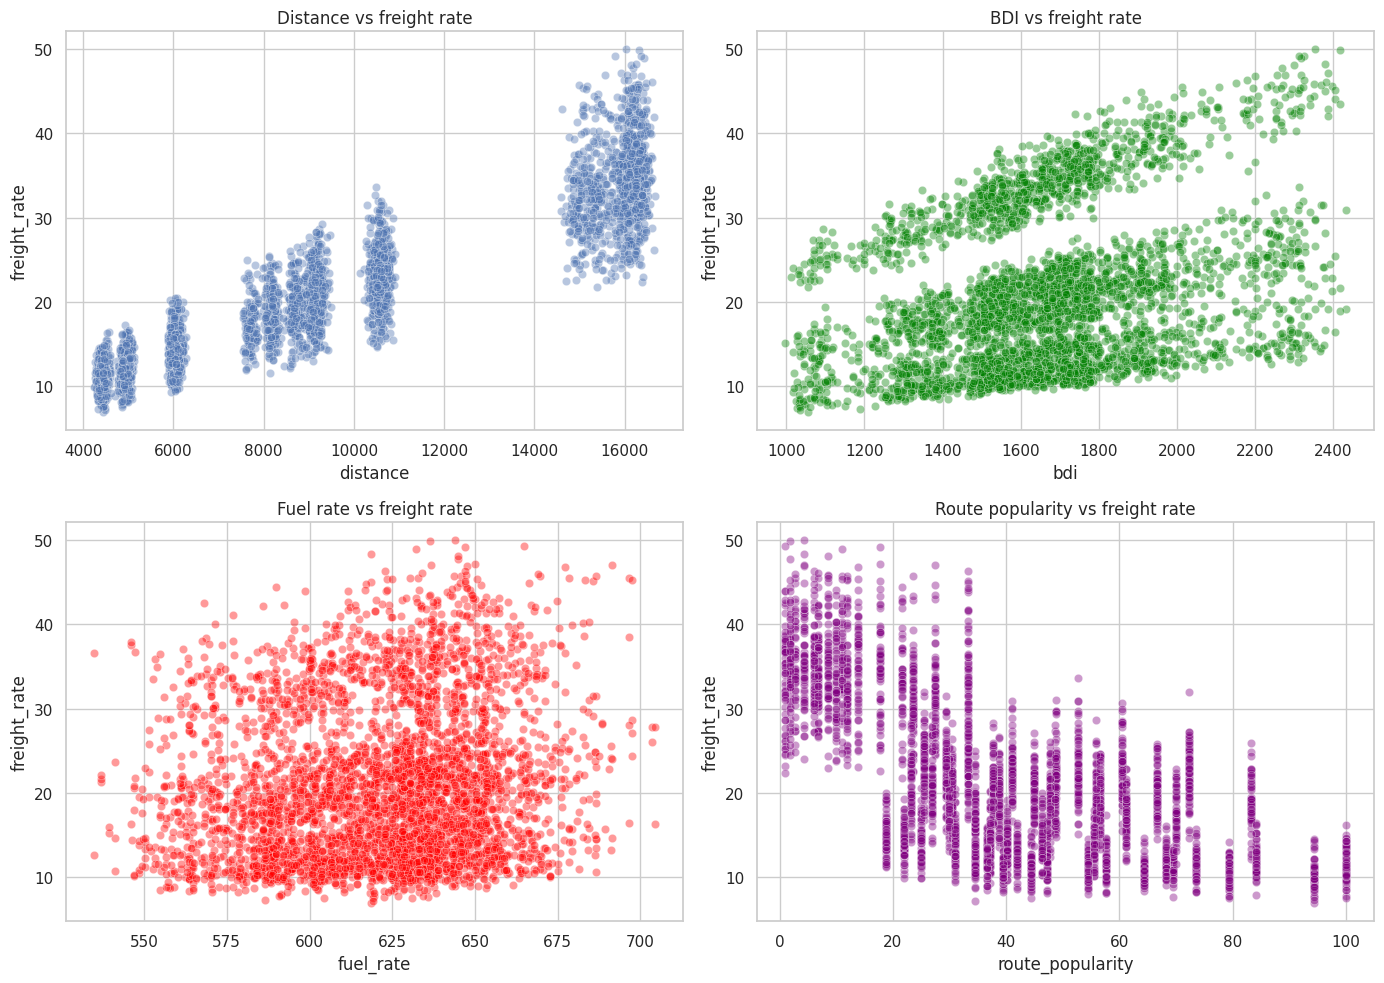

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.scatterplot(x="distance", y="freight_rate", data=df.sample(4000, random_state=1), alpha=0.4, ax=axes[0,0])
axes[0,0].set_title("Distance vs freight rate")
sns.scatterplot(x="bdi", y="freight_rate", data=df.sample(4000, random_state=1), alpha=0.4, ax=axes[0,1], color="green")
axes[0,1].set_title("BDI vs freight rate")
sns.scatterplot(x="fuel_rate", y="freight_rate", data=df.sample(4000, random_state=1), alpha=0.4, ax=axes[1,0], color="red")
axes[1,0].set_title("Fuel rate vs freight rate")
sns.scatterplot(x="route_popularity", y="freight_rate", data=df.sample(4000, random_state=1), alpha=0.4, ax=axes[1,1], color="purple")
axes[1,1].set_title("Route popularity vs freight rate")
plt.tight_layout(); plt.show()

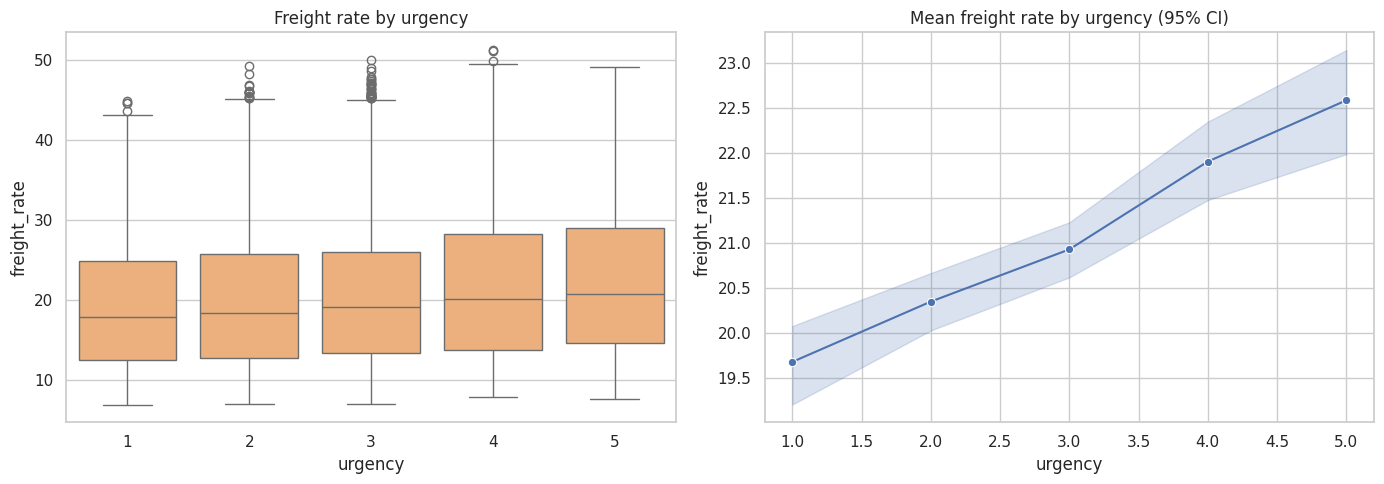

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x="urgency", y="freight_rate", data=df, ax=ax[0], color="#fdae6b")
ax[0].set_title("Freight rate by urgency")
sns.lineplot(x="urgency", y="freight_rate", data=df, marker="o", ax=ax[1])
ax[1].set_title("Mean freight rate by urgency (95% CI)")
plt.tight_layout(); plt.show()

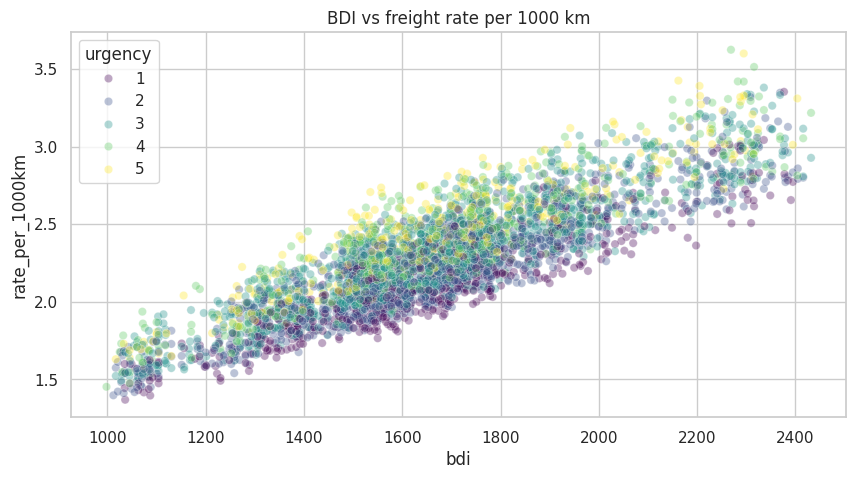

In [13]:
# Rate per km removes the dominant distance effect so other drivers are easier to see
df["rate_per_1000km"] = df.freight_rate / df.distance * 1000
sns.scatterplot(x="bdi", y="rate_per_1000km", data=df.sample(4000, random_state=1), alpha=0.35, hue="urgency", palette="viridis")
plt.title("BDI vs freight rate per 1000 km"); plt.show()

## 4. Outlier check (IQR method)

In [14]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()

out = pd.DataFrame({"outliers": {c: iqr_outliers(df[c]) for c in num_cols + ["rate_per_1000km"]}})
out["% of rows"] = out.outliers / len(df) * 100
out

,outliers,% of rows
distance,0,0.00
route_popularity,0,0.00
fuel_rate,0,0.00
bdi,486,4.44
freight_rate,35,0.32
rate_per_1000km,142,1.30


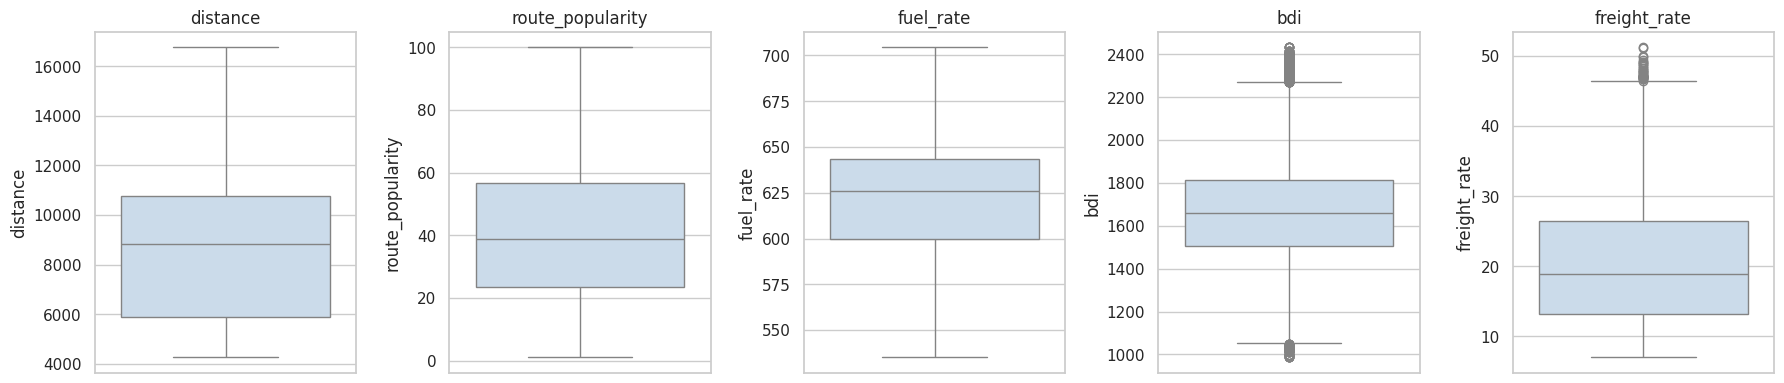

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#c6dbef"); ax.set_title(col)
plt.tight_layout(); plt.show()

Outliers are a very small share of rows, so no rows need to be removed.

## 5. Encoding & feature engineering
The dataset has no free-text categories, so encoding focuses on:
- **Date** → calendar features, with **cyclical (sin/cos) encoding** for month and day-of-year so December and January stay close.
- **Urgency** → kept as an **ordinal** integer (order matters), plus **one-hot** columns for models that don't assume order.
- **Route popularity** → binned into categories (Low / Medium / High / Very High), then **label-encoded** (ordinal) and **one-hot encoded**.
- **Distance** → binned into voyage-length classes (Short / Medium / Long / Ultra-long) and encoded.
- **Numeric features** → standardised copy for distance-based / neural models (LSTM etc.).

In [16]:
enc = df.copy()

# --- Date features ---
enc["year"] = enc.date.dt.year
enc["month"] = enc.date.dt.month
enc["quarter"] = enc.date.dt.quarter
enc["day_of_year"] = enc.date.dt.dayofyear
enc["day_of_week"] = enc.date.dt.dayofweek
enc["is_monsoon"] = enc.month.isin([6, 7, 8, 9]).astype(int)

# Cyclical encoding
enc["month_sin"] = np.sin(2*np.pi*enc.month/12)
enc["month_cos"] = np.cos(2*np.pi*enc.month/12)
enc["doy_sin"] = np.sin(2*np.pi*enc.day_of_year/365)
enc["doy_cos"] = np.cos(2*np.pi*enc.day_of_year/365)

enc[["date", "month", "month_sin", "month_cos", "is_monsoon"]].head()

,date,month,month_sin,month_cos,is_monsoon
0,2021-01-01,1,0.50,0.87,0
1,2021-01-01,1,0.50,0.87,0
2,2021-01-01,1,0.50,0.87,0
3,2021-01-01,1,0.50,0.87,0
4,2021-01-01,1,0.50,0.87,0


In [17]:
# --- Binning + ordinal (label) encoding ---
pop_labels = ["Low", "Medium", "High", "Very High"]
enc["popularity_class"] = pd.qcut(enc.route_popularity, q=4, labels=pop_labels)
enc["popularity_class_code"] = enc.popularity_class.cat.codes          # 0..3 (ordinal)

dist_labels = ["Short", "Medium", "Long", "Ultra-long"]
enc["distance_class"] = pd.qcut(enc.distance, q=4, labels=dist_labels)
enc["distance_class_code"] = enc.distance_class.cat.codes

enc[["route_popularity", "popularity_class", "popularity_class_code",
     "distance", "distance_class", "distance_class_code"]].sample(8, random_state=2)

,route_popularity,popularity_class,popularity_class_code,distance,distance_class,distance_class_code
1988,70.00,Very High,3,"8,210.80",Medium,1
6844,29.40,Medium,1,"10,633.40",Long,2
4158,25.50,Medium,1,"10,694.20",Long,2
9182,48.80,High,2,"10,622.70",Long,2
3108,66.60,Very High,3,"9,029.20",Long,2
3575,48.80,High,2,"10,529.30",Long,2
8869,40.20,High,2,"6,014.80",Medium,1
3905,41.90,High,2,"4,921.90",Short,0


In [18]:
# --- One-hot encoding ---
enc = pd.get_dummies(enc, columns=["urgency", "popularity_class", "distance_class"],
                     prefix=["urgency", "pop", "dist"], dtype=int)
# urgency ordinal is still needed as numeric -> restore from df
enc["urgency"] = df["urgency"].values
print("Columns after encoding:", enc.shape[1])
enc.filter(regex="^(urgency|pop_|dist_)").head()

Columns after encoding: 33


,urgency_1,urgency_2,urgency_3,urgency_4,urgency_5,pop_Low,pop_Medium,pop_High,pop_Very High,dist_Short,dist_Medium,dist_Long,dist_Ultra-long,urgency
0,0,0,1,0,0,1,0,0,0,0,0,0,1,3
1,1,0,0,0,0,0,1,0,0,0,0,1,0,1
2,0,1,0,0,0,0,0,0,1,0,1,0,0,2
3,0,1,0,0,0,0,1,0,0,1,0,0,0,2
4,0,0,1,0,0,1,0,0,0,0,0,1,0,3


In [19]:
# --- Scaling (standardised copy for NN / distance-based models) ---
scale_cols = ["distance", "route_popularity", "fuel_rate", "bdi"]
scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(enc[scale_cols]),
                      columns=[c + "_scaled" for c in scale_cols], index=enc.index)
enc = pd.concat([enc, scaled], axis=1)
scaled.describe().T[["mean", "std"]]

,mean,std
distance_scaled,0.00,1.00
route_popularity_scaled,-0.00,1.00
fuel_rate_scaled,-0.00,1.00
bdi_scaled,-0.00,1.00


## 6. Correlation heatmap
### 6.1 Core features

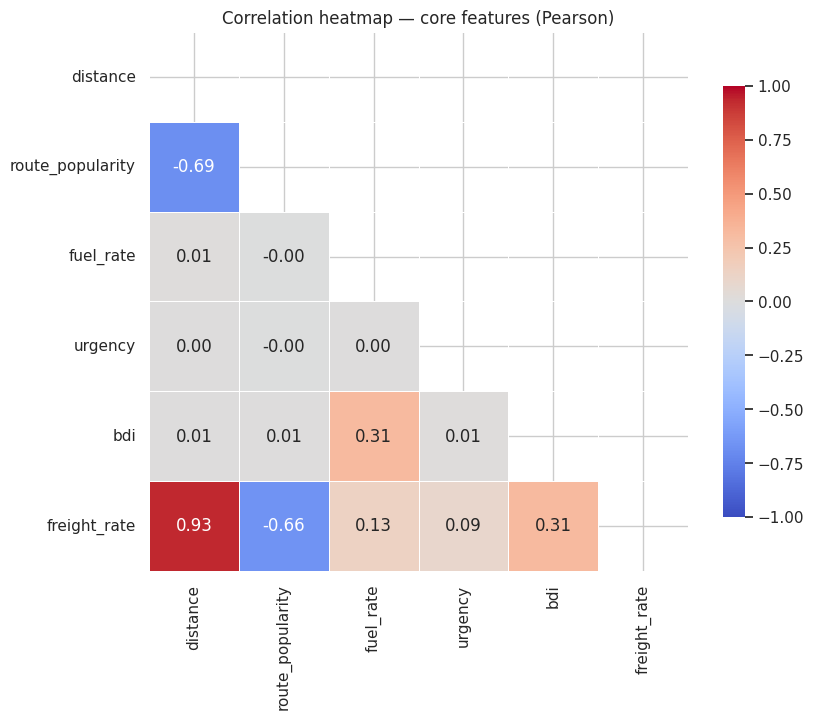

In [20]:
core = ["distance", "route_popularity", "fuel_rate", "urgency", "bdi", "freight_rate"]
corr = df[core].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            mask=mask, linewidths=.5, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap — core features (Pearson)")
plt.show()

In [21]:
corr[["freight_rate"]].drop("freight_rate").sort_values("freight_rate", ascending=False)

,freight_rate
distance,0.93
bdi,0.31
fuel_rate,0.13
urgency,0.09
route_popularity,-0.66


### 6.2 Spearman (rank) correlation — captures monotonic non-linear relationships

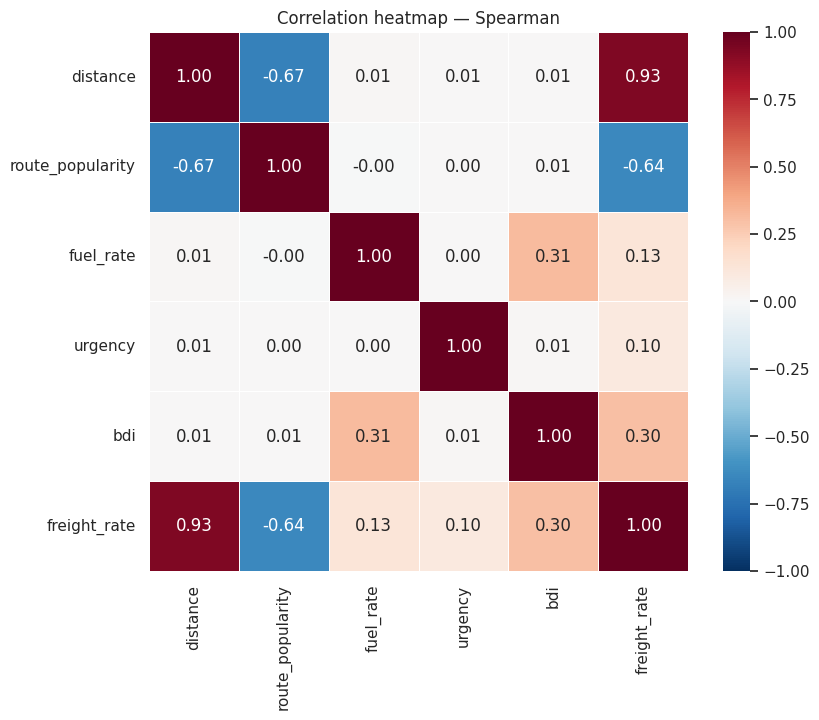

In [22]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[core].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=.5, square=True)
plt.title("Correlation heatmap — Spearman")
plt.show()

### 6.3 Full heatmap with engineered features

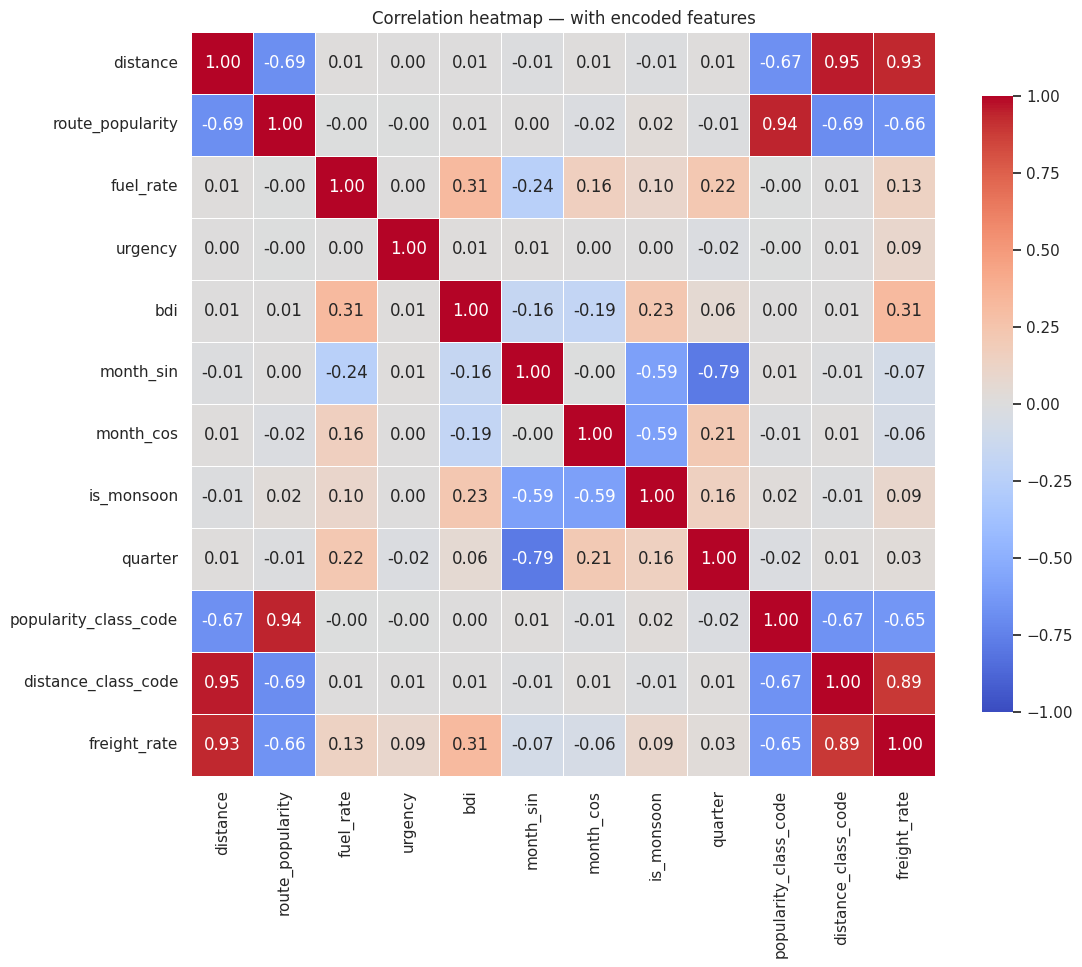

In [23]:
eng_cols = ["distance", "route_popularity", "fuel_rate", "urgency", "bdi",
            "month_sin", "month_cos", "is_monsoon", "quarter",
            "popularity_class_code", "distance_class_code", "freight_rate"]
plt.figure(figsize=(12, 10))
sns.heatmap(enc[eng_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=.4, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap — with encoded features")
plt.show()

In [24]:
# Multicollinearity check (VIF) on core predictors
from numpy.linalg import inv
X = df[["distance", "route_popularity", "fuel_rate", "urgency", "bdi"]]
Xs = (X - X.mean()) / X.std()
vif = pd.Series(np.diag(inv(Xs.corr().values)), index=X.columns, name="VIF")
vif.to_frame()

,VIF
distance,1.90
route_popularity,1.90
fuel_rate,1.11
urgency,1.00
bdi,1.11


### Key takeaways
- **Distance** is the strongest driver of freight rate (strong positive correlation).
- **Route popularity** is negatively correlated with rate — but it is also correlated with distance (busy lanes are the shorter Indonesian/Australian ones), so part of that effect is shared.
- **BDI, fuel rate and urgency** have weaker linear correlation on their own, yet matter once distance is accounted for (see the rate-per-1000 km plot).
- VIF values are low, so multicollinearity is not a problem for tree models or linear models.

## 7. Save model-ready data

In [25]:
enc.drop(columns=["date", "rate_per_1000km"]).to_csv("freight_dataset_encoded.csv", index=False)
print("Saved freight_dataset_encoded.csv (target-derived rate_per_1000km excluded to avoid leakage)", enc.shape)
enc.head()

Saved freight_dataset_encoded.csv (target-derived rate_per_1000km excluded to avoid leakage) (10956, 37)


,date,distance,route_popularity,fuel_rate,bdi,freight_rate,year,month,rate_per_1000km,quarter,...,pop_Very High,dist_Short,dist_Medium,dist_Long,dist_Ultra-long,urgency,distance_scaled,route_popularity_scaled,fuel_rate_scaled,bdi_scaled
0,2021-01-01,"15,378.00",23.50,600.00,"1,800.00",32.85,2021,1,2.14,1,...,0,0,0,0,1,3,1.44,-0.73,-0.71,0.46
1,2021-01-01,"9,116.90",37.70,600.00,"1,800.00",20.68,2021,1,2.27,1,...,0,0,0,1,0,1,-0.05,-0.13,-0.71,0.46
2,2021-01-01,"8,589.90",83.30,600.00,"1,800.00",19.26,2021,1,2.24,1,...,1,0,1,0,0,2,-0.18,1.77,-0.71,0.46
3,2021-01-01,"4,409.10",34.40,600.00,"1,800.00",11.07,2021,1,2.51,1,...,0,1,0,0,0,2,-1.18,-0.27,-0.71,0.46
4,2021-01-01,"9,090.70",23.20,600.00,"1,800.00",22.19,2021,1,2.44,1,...,0,0,0,1,0,3,-0.06,-0.74,-0.71,0.46
